### 1. Feature Engineering and Standardization

In [1]:
import pandas as pd
import numpy as np

# Load original dataset
df = pd.read_csv("../data/creditcard.csv")

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Sort chronologically
df_clean = df_clean.sort_values("Time").reset_index(drop=True)

# Create chronological splits
n = len(df_clean)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df_clean.iloc[:train_end].copy()
val_df = df_clean.iloc[train_end:val_end].copy()
test_df = df_clean.iloc[val_end:].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (198608, 31)
Validation: (42559, 31)
Testing: (42559, 31)


In [2]:
from sklearn.preprocessing import StandardScaler

# Separate input features and target label
feature_columns = [
    col for col in train_df.columns
    if col != "Class"
]

# Extract legitimate training transactions only
X_train_legit = train_df.loc[
    train_df["Class"] == 0,
    feature_columns
]

# Keep labels separately for evaluation
y_val = val_df["Class"].copy()
y_test = test_df["Class"].copy()

# Extract validation and test features
X_val = val_df[feature_columns]
X_test = test_df[feature_columns]

# Initialize scaler
scaler = StandardScaler()

# Fit ONLY on legitimate training transactions
X_train_scaled = scaler.fit_transform(X_train_legit)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Check dimensions
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

# Check scaled feature statistics
print("\nTraining scaled means (first 5 features):")
print(X_train_scaled.mean(axis=0)[:5])

print("\nTraining scaled standard deviations (first 5 features):")
print(X_train_scaled.std(axis=0)[:5])

Training shape: (198242, 30)
Validation shape: (42559, 30)
Testing shape: (42559, 30)

Training scaled means (first 5 features):
[ 7.34048044e-17 -1.83512011e-17 -2.06451012e-17 -3.67024022e-17
  9.17560055e-18]

Training scaled standard deviations (first 5 features):
[1. 1. 1. 1. 1.]


### 2. Gaussian Mixture Model - Component Selection

In [3]:

from sklearn.mixture import GaussianMixture
import pandas as pd
import matplotlib.pyplot as plt

# Extract legitimate validation transactions only
# Use standardized features to match GMM training data
X_val_legit_scaled = X_val_scaled[
    y_val.to_numpy() == 0
]

print("Legitimate validation shape:", X_val_legit_scaled.shape)

# Candidate number of Gaussian components
component_range = range(1, 16)

results = []
gmm_models = {}

# Train and evaluate different GMM configurations
for k in component_range:

    print(f"Training GMM with {k} components...")

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        max_iter=200,
        n_init=3,
        reg_covar=1e-5,
        random_state=42
    )

    # Train ONLY on legitimate training transactions
    gmm.fit(X_train_scaled)

    # Calculate AIC and BIC on training data
    aic = gmm.aic(X_train_scaled)
    bic = gmm.bic(X_train_scaled)

    # Evaluate on legitimate validation transactions
    val_log_likelihood = gmm.score(X_val_legit_scaled)

    # Store results
    results.append({
        "Components": k,
        "AIC": aic,
        "BIC": bic,
        "Validation Log Likelihood": val_log_likelihood,
        "Converged": gmm.converged_,
        "Iterations": gmm.n_iter_
    })

    # Save trained models
    gmm_models[k] = gmm

# Display results
results_df = pd.DataFrame(results)

display(results_df)

# Identify best validation model
best_k = results_df.loc[
    results_df["Validation Log Likelihood"].idxmax(),
    "Components"
]

print(f"\nBest component count based on validation: {best_k}")

Legitimate validation shape: (42504, 30)
Training GMM with 1 components...
Training GMM with 2 components...
Training GMM with 3 components...
Training GMM with 4 components...
Training GMM with 5 components...
Training GMM with 6 components...
Training GMM with 7 components...
Training GMM with 8 components...
Training GMM with 9 components...
Training GMM with 10 components...
Training GMM with 11 components...
Training GMM with 12 components...
Training GMM with 13 components...
Training GMM with 14 components...
Training GMM with 15 components...


,Components,AIC,BIC,Validation Log Likelihood,Converged,Iterations
0,1,1.687771e+07,1.687832e+07,-46.737598,True,2
1,2,1.421530e+07,1.421654e+07,-39.889779,True,14
2,3,1.352354e+07,1.352540e+07,-38.638756,True,37
3,4,1.307618e+07,1.307866e+07,-37.667309,True,32
4,5,1.262946e+07,1.263256e+07,-35.796551,True,59
5,6,1.232484e+07,1.232856e+07,-35.786210,True,36
6,7,1.211716e+07,1.212151e+07,-35.417367,True,25
7,8,1.203926e+07,1.204423e+07,-35.294439,True,32
8,9,1.182614e+07,1.183173e+07,-34.910119,True,79
9,10,1.168685e+07,1.169306e+07,-34.607598,True,35



Best component count based on validation: 11


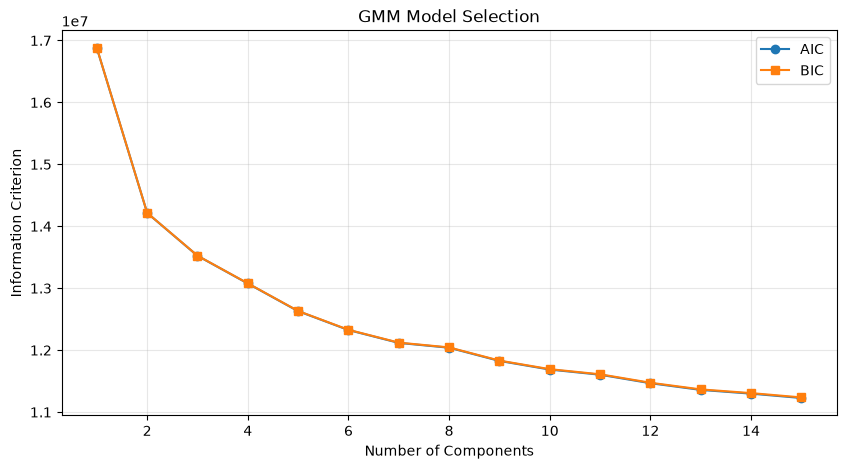

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Components"],
    results_df["AIC"],
    marker="o",
    label="AIC"
)

plt.plot(
    results_df["Components"],
    results_df["BIC"],
    marker="s",
    label="BIC"
)

plt.xlabel("Number of Components")
plt.ylabel("Information Criterion")
plt.title("GMM Model Selection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:

# 2.1 Extended GMM Component Search (K = 16 to 25)

from sklearn.mixture import GaussianMixture
import pandas as pd

extended_results = []

# Test additional component counts
for k in range(16, 26):

    print(f"Training extended GMM with {k} components...")

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        max_iter=200,
        n_init=3,
        reg_covar=1e-5,
        random_state=42
    )

    # Train exclusively on legitimate training transactions
    gmm.fit(X_train_scaled)

    # Evaluate using legitimate validation transactions
    val_log_likelihood = gmm.score(X_val_legit_scaled)

    # Calculate training information criteria
    aic = gmm.aic(X_train_scaled)
    bic = gmm.bic(X_train_scaled)

    extended_results.append({
        "Components": k,
        "AIC": aic,
        "BIC": bic,
        "Validation Log Likelihood": val_log_likelihood,
        "Converged": gmm.converged_,
        "Iterations": gmm.n_iter_
    })

    # Store additional models without deleting existing ones
    gmm_models[k] = gmm

# Store extended results separately
extended_results_df = pd.DataFrame(extended_results)

display(extended_results_df)

# Identify the best model in the extended search
extended_best = extended_results_df.loc[
    extended_results_df["Validation Log Likelihood"].idxmax()
]

print("\nBest extended component count:", int(extended_best["Components"]))
print("Best extended validation log-likelihood:",
      extended_best["Validation Log Likelihood"])


Training extended GMM with 16 components...
Training extended GMM with 17 components...
Training extended GMM with 18 components...
Training extended GMM with 19 components...
Training extended GMM with 20 components...
Training extended GMM with 21 components...
Training extended GMM with 22 components...
Training extended GMM with 23 components...
Training extended GMM with 24 components...
Training extended GMM with 25 components...


,Components,AIC,BIC,Validation Log Likelihood,Converged,Iterations
0,16,1.109734e+07,1.110728e+07,-33.240925,True,55
1,17,1.102168e+07,1.103224e+07,-33.884478,True,30
2,18,1.097295e+07,1.098413e+07,-33.649435,True,42
3,19,1.090050e+07,1.091231e+07,-33.040445,True,52
4,20,1.082293e+07,1.083536e+07,-33.168837,True,72
5,21,1.075882e+07,1.077187e+07,-32.642249,True,44
6,22,1.069415e+07,1.070782e+07,-32.649438,True,48
7,23,1.067234e+07,1.068664e+07,-32.996276,True,74
8,24,1.065570e+07,1.067062e+07,-33.163348,True,55
9,25,1.053761e+07,1.055315e+07,-32.634872,True,48



Best extended component count: 25
Best extended validation log-likelihood: -32.63487161665817


In [6]:

# 2.2 Further Extended GMM Search (K = 26 to 40)

further_results = []

for k in range(26, 41):

    print(f"Training GMM with {k} components...")

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        max_iter=200,
        n_init=3,
        reg_covar=1e-5,
        random_state=42
    )

    # Train only on legitimate training transactions
    gmm.fit(X_train_scaled)

    # Evaluate on legitimate validation transactions
    val_ll = gmm.score(X_val_legit_scaled)

    further_results.append({
        "Components": k,
        "AIC": gmm.aic(X_train_scaled),
        "BIC": gmm.bic(X_train_scaled),
        "Validation Log Likelihood": val_ll,
        "Converged": gmm.converged_,
        "Iterations": gmm.n_iter_
    })

    gmm_models[k] = gmm

further_results_df = pd.DataFrame(further_results)

display(further_results_df)

# Best candidate in this search range
further_best = further_results_df.loc[
    further_results_df["Validation Log Likelihood"].idxmax()
]

print("\nBest component count:", int(further_best["Components"]))
print("Best validation log-likelihood:",
      further_best["Validation Log Likelihood"])


Training GMM with 26 components...
Training GMM with 27 components...
Training GMM with 28 components...
Training GMM with 29 components...
Training GMM with 30 components...
Training GMM with 31 components...
Training GMM with 32 components...
Training GMM with 33 components...
Training GMM with 34 components...
Training GMM with 35 components...
Training GMM with 36 components...
Training GMM with 37 components...
Training GMM with 38 components...
Training GMM with 39 components...
Training GMM with 40 components...


,Components,AIC,BIC,Validation Log Likelihood,Converged,Iterations
0,26,1.049729e+07,1.051345e+07,-32.320581,True,46
1,27,1.044061e+07,1.045740e+07,-31.759501,True,57
2,28,1.039660e+07,1.041401e+07,-32.634290,True,41
3,29,1.033725e+07,1.035528e+07,-32.331546,True,50
4,30,1.026661e+07,1.028526e+07,-31.485128,True,42
5,31,1.021390e+07,1.023318e+07,-31.400528,True,67
6,32,1.015283e+07,1.017272e+07,-31.103500,True,67
7,33,1.012249e+07,1.014301e+07,-31.273180,True,51
8,34,1.010222e+07,1.012336e+07,-31.089774,True,51
9,35,1.009889e+07,1.012065e+07,-31.516823,True,35



Best component count: 36
Best validation log-likelihood: -30.7258571054145


,Components,AIC,BIC,Validation Log Likelihood,Converged,Iterations
0,1,1.687771e+07,1.687832e+07,-46.737598,True,2
1,2,1.421530e+07,1.421654e+07,-39.889779,True,14
2,3,1.352354e+07,1.352540e+07,-38.638756,True,37
3,4,1.307618e+07,1.307866e+07,-37.667309,True,32
4,5,1.262946e+07,1.263256e+07,-35.796551,True,59
5,6,1.232484e+07,1.232856e+07,-35.786210,True,36
6,7,1.211716e+07,1.212151e+07,-35.417367,True,25
7,8,1.203926e+07,1.204423e+07,-35.294439,True,32
8,9,1.182614e+07,1.183173e+07,-34.910119,True,79
9,10,1.168685e+07,1.169306e+07,-34.607598,True,35



OVERALL BEST MODEL
Components: 36
Validation Log Likelihood: -30.7258571054145

Convergence summary:
Converged
True    40
Name: count, dtype: int64


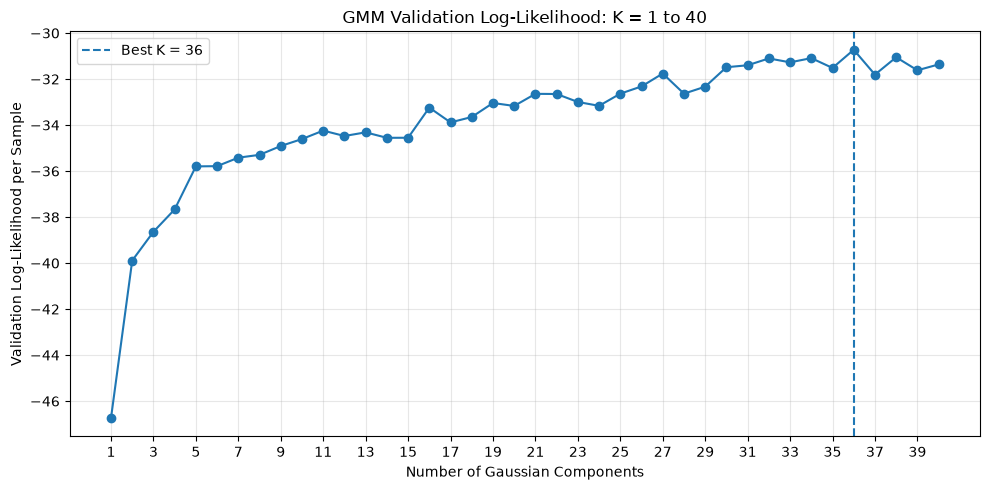

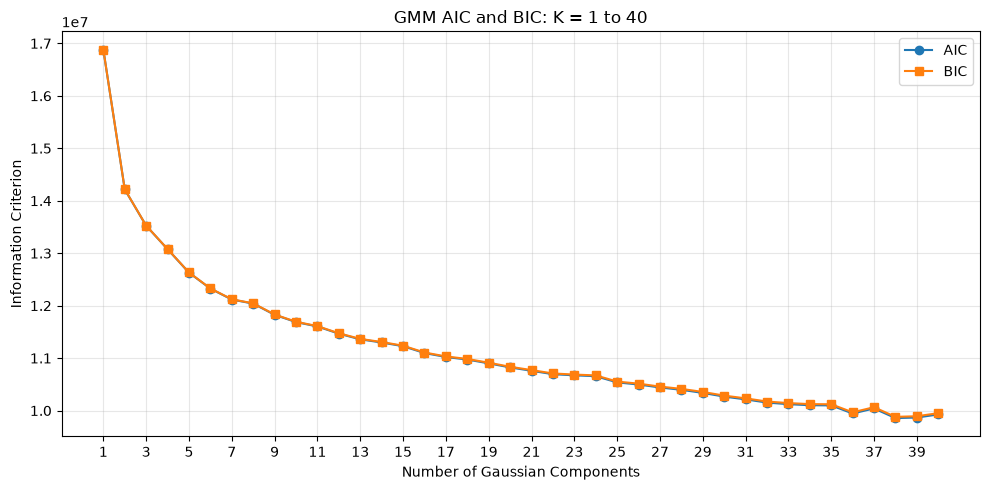

In [7]:

# 2.3 Consolidated GMM Model Selection (K = 1 to 40)

import pandas as pd
import matplotlib.pyplot as plt

# Combine all three experiment ranges
all_gmm_results = pd.concat(
    [
        results_df,
        extended_results_df,
        further_results_df
    ],
    ignore_index=True
).sort_values("Components").reset_index(drop=True)

# Display complete comparison
display(all_gmm_results)

# Find the best validation log-likelihood
overall_best = all_gmm_results.loc[
    all_gmm_results["Validation Log Likelihood"].idxmax()
]

print("\nOVERALL BEST MODEL")
print("Components:", int(overall_best["Components"]))
print("Validation Log Likelihood:",
      overall_best["Validation Log Likelihood"])

print("\nConvergence summary:")
print(all_gmm_results["Converged"].value_counts())

# Plot validation log-likelihood
plt.figure(figsize=(10, 5))

plt.plot(
    all_gmm_results["Components"],
    all_gmm_results["Validation Log Likelihood"],
    marker="o"
)

plt.axvline(
    x=overall_best["Components"],
    linestyle="--",
    label=f"Best K = {int(overall_best['Components'])}"
)

plt.xlabel("Number of Gaussian Components")
plt.ylabel("Validation Log-Likelihood per Sample")
plt.title("GMM Validation Log-Likelihood: K = 1 to 40")
plt.xticks(range(1, 41, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot AIC and BIC
plt.figure(figsize=(10, 5))

plt.plot(
    all_gmm_results["Components"],
    all_gmm_results["AIC"],
    marker="o",
    label="AIC"
)

plt.plot(
    all_gmm_results["Components"],
    all_gmm_results["BIC"],
    marker="s",
    label="BIC"
)

plt.xlabel("Number of Gaussian Components")
plt.ylabel("Information Criterion")
plt.title("GMM AIC and BIC: K = 1 to 40")
plt.xticks(range(1, 41, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [8]:

# 2.4 Stability Comparison: K=36 vs K=38

stability_results = []

for k in [36, 38]:

    for seed in [21, 42, 123, 2026, 7]:

        print(f"Testing K={k}, seed={seed}")

        model = GaussianMixture(
            n_components=k,
            covariance_type="diag",
            max_iter=200,
            n_init=1,
            reg_covar=1e-5,
            random_state=seed
        )

        model.fit(X_train_scaled)

        val_ll = model.score(X_val_legit_scaled)

        stability_results.append({
            "Components": k,
            "Seed": seed,
            "Validation Log Likelihood": val_ll,
            "Converged": model.converged_,
            "Iterations": model.n_iter_
        })

stability_df = pd.DataFrame(stability_results)

print("\nIndividual results:")
display(stability_df)

print("\nStability summary:")
stability_summary = (
    stability_df.groupby("Components")["Validation Log Likelihood"]
    .agg(["mean", "std", "min", "max"])
)

display(stability_summary)


Testing K=36, seed=21
Testing K=36, seed=42
Testing K=36, seed=123
Testing K=36, seed=2026
Testing K=36, seed=7
Testing K=38, seed=21
Testing K=38, seed=42
Testing K=38, seed=123
Testing K=38, seed=2026
Testing K=38, seed=7

Individual results:


,Components,Seed,Validation Log Likelihood,Converged,Iterations
0,36,21,-32.321935,True,36
1,36,42,-31.330949,True,44
2,36,123,-31.337319,True,42
3,36,2026,-32.106453,True,35
4,36,7,-31.491292,True,88
5,38,21,-31.870173,True,42
6,38,42,-31.661115,True,64
7,38,123,-31.362023,True,106
8,38,2026,-31.482662,True,49
9,38,7,-31.251129,True,59



Stability summary:


,mean,std,min,max
Components,,,,
36,-31.717589,0.464154,-32.321935,-31.330949
38,-31.525421,0.245474,-31.870173,-31.251129


In [9]:

# 2.5 Final Stability Comparison (n_init=3)

final_stability_results = []

for k in [36, 38]:

    for seed in [21, 42, 123, 2026, 7]:

        print(f"Testing K={k}, seed={seed}, n_init=3")

        model = GaussianMixture(
            n_components=k,
            covariance_type="diag",
            max_iter=200,
            n_init=3,
            reg_covar=1e-5,
            random_state=seed
        )

        model.fit(X_train_scaled)

        val_ll = model.score(X_val_legit_scaled)

        final_stability_results.append({
            "Components": k,
            "Seed": seed,
            "Validation Log Likelihood": val_ll,
            "Converged": model.converged_,
            "Iterations": model.n_iter_
        })

final_stability_df = pd.DataFrame(final_stability_results)

print("\nIndividual results:")
display(final_stability_df)

print("\nFinal stability summary:")

final_stability_summary = (
    final_stability_df
    .groupby("Components")["Validation Log Likelihood"]
    .agg(["mean", "std", "min", "max"])
)

display(final_stability_summary)

# Compare average validation likelihood
if (
    final_stability_summary.loc[36, "mean"]
    > final_stability_summary.loc[38, "mean"]
):
    print("\nK=36 has the higher mean validation log-likelihood.")
else:
    print("\nK=38 has the higher mean validation log-likelihood.")


Testing K=36, seed=21, n_init=3
Testing K=36, seed=42, n_init=3
Testing K=36, seed=123, n_init=3
Testing K=36, seed=2026, n_init=3
Testing K=36, seed=7, n_init=3
Testing K=38, seed=21, n_init=3
Testing K=38, seed=42, n_init=3
Testing K=38, seed=123, n_init=3
Testing K=38, seed=2026, n_init=3
Testing K=38, seed=7, n_init=3

Individual results:


,Components,Seed,Validation Log Likelihood,Converged,Iterations
0,36,21,-31.419961,True,52
1,36,42,-30.725857,True,48
2,36,123,-31.926193,True,55
3,36,2026,-31.916366,True,36
4,36,7,-31.491292,True,88
5,38,21,-32.270942,True,97
6,38,42,-31.052333,True,111
7,38,123,-31.362023,True,106
8,38,2026,-31.482662,True,49
9,38,7,-31.251129,True,59



Final stability summary:


,mean,std,min,max
Components,,,,
36,-31.495934,0.490076,-31.926193,-30.725857
38,-31.483818,0.467633,-32.270942,-31.052333



K=38 has the higher mean validation log-likelihood.


In [10]:

# 2.6 Paired Stability Comparison

paired_scores = final_stability_df.pivot(
    index="Seed",
    columns="Components",
    values="Validation Log Likelihood"
)

paired_scores["K38_minus_K36"] = (
    paired_scores[38] - paired_scores[36]
)

display(paired_scores)

print(
    "\nSeeds where K=38 performed better:",
    (paired_scores["K38_minus_K36"] > 0).sum()
)

print(
    "Seeds where K=36 performed better:",
    (paired_scores["K38_minus_K36"] < 0).sum()
)

print(
    "Mean paired difference:",
    paired_scores["K38_minus_K36"].mean()
)


Components,36,38,K38_minus_K36
Seed,,,
7,-31.491292,-31.251129,0.240163
21,-31.419961,-32.270942,-0.850981
42,-30.725857,-31.052333,-0.326476
123,-31.926193,-31.362023,0.564171
2026,-31.916366,-31.482662,0.433704



Seeds where K=38 performed better: 3
Seeds where K=36 performed better: 2
Mean paired difference: 0.012115946671811173



### 2.7 Final Model Selection Rationale

The component search identified K=36 as the configuration
with the highest single-run validation log-likelihood.
However, K=38 achieved the lowest AIC and BIC values among
the 40 tested configurations.

Repeated initialization experiments using five random
seeds showed that K=38 achieved a slightly higher mean
validation log-likelihood than K=36. The paired comparison
favoured K=38 in three out of five runs.

The difference was small, and therefore K=38 is selected
as a practical candidate based on the combined evidence
from information criteria and initialization stability,
rather than being claimed as a globally optimal solution.


Initial Baseline Evaluation — GMM K=11

In [11]:

#Initial Baseline Evaluation — GMM K=11

# Select the GMM with the best validation log-likelihood
best_gmm = gmm_models[int(best_k)]

# Calculate negative log-likelihood (NLL)
# Higher NLL = more anomalous transaction
val_anomaly_scores = -best_gmm.score_samples(X_val_scaled)
test_anomaly_scores = -best_gmm.score_samples(X_test_scaled)

print("Selected GMM components:", best_k)

print("\nValidation anomaly scores:")
print("Minimum:", val_anomaly_scores.min())
print("Maximum:", val_anomaly_scores.max())
print("Mean:", val_anomaly_scores.mean())

print("\nTest anomaly scores:")
print("Minimum:", test_anomaly_scores.min())
print("Maximum:", test_anomaly_scores.max())
print("Mean:", test_anomaly_scores.mean())

# Analyze validation scores using known validation labels
val_scores_df = pd.DataFrame({
    "Anomaly Score": val_anomaly_scores,
    "Actual Class": y_val.to_numpy()
})

print("\nValidation score distribution by class:")
display(
    val_scores_df.groupby("Actual Class")["Anomaly Score"]
    .agg(["count", "mean", "median", "min", "max"])
)


Selected GMM components: 11

Validation anomaly scores:
Minimum: 12.322971889889246
Maximum: 362.2839916559892
Mean: 34.301867512866195

Test anomaly scores:
Minimum: 16.472417641015497
Maximum: 2043.5033723913634
Mean: 35.54872234368853

Validation score distribution by class:


,count,mean,median,min,max
Actual Class,,,,,
0,42504,34.240970,32.099903,12.322972,362.283992
1,55,81.363737,87.970204,23.010862,124.824742


In [12]:

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Use validation data only for threshold selection
val_labels = y_val.to_numpy()

# Calculate Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(
    val_labels,
    val_anomaly_scores
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Select threshold with maximum validation F1-score
best_threshold_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_idx]

# Predictions using selected threshold
val_predictions = (
    val_anomaly_scores >= best_threshold
).astype(int)

# Validation metrics
val_pr_auc = average_precision_score(
    val_labels,
    val_anomaly_scores
)

print("Selected threshold:", best_threshold)
print("Validation PR-AUC:", val_pr_auc)
print("Validation Precision:", precision[best_threshold_idx])
print("Validation Recall:", recall[best_threshold_idx])
print("Validation F1-score:", f1_scores[best_threshold_idx])

print("\nConfusion Matrix:")
print(confusion_matrix(val_labels, val_predictions))

print("\nClassification Report:")
print(classification_report(
    val_labels,
    val_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))


Selected threshold: 87.97020395879801
Validation PR-AUC: 0.11134720983777256
Validation Precision: 0.20588235294117646
Validation Recall: 0.509090909090909
Validation F1-score: 0.29319371723647925

Confusion Matrix:
[[42396   108]
 [   27    28]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42504
       Fraud       0.21      0.51      0.29        55

    accuracy                           1.00     42559
   macro avg       0.60      0.75      0.65     42559
weighted avg       1.00      1.00      1.00     42559



In [13]:

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Apply the validation-selected threshold to test scores
test_labels = y_test.to_numpy()

test_predictions = (
    test_anomaly_scores >= best_threshold
).astype(int)

# Evaluate test performance
test_pr_auc = average_precision_score(
    test_labels,
    test_anomaly_scores
)

test_precision = precision_score(
    test_labels, test_predictions, zero_division=0
)

test_recall = recall_score(
    test_labels, test_predictions, zero_division=0
)

test_f1 = f1_score(
    test_labels, test_predictions, zero_division=0
)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1]
).ravel()

# False Positive Rate
false_positive_rate = fp / (fp + tn)

print("FINAL TEST RESULTS")
print("-------------------")
print("Selected threshold:", best_threshold)
print("Test fraud prevalence:", test_labels.mean())
print("Test PR-AUC (Average Precision):", test_pr_auc)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1)
print("False Positive Rate:", false_positive_rate)

print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, test_predictions, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("\nTransaction Summary:")
print("Total transactions:", len(test_labels))
print("Fraud transactions detected:", tp)
print("Fraud transactions missed:", fn)
print("Legitimate transactions incorrectly flagged:", fp)


FINAL TEST RESULTS
-------------------
Selected threshold: 87.97020395879801
Test fraud prevalence: 0.001221833219765502
Test PR-AUC (Average Precision): 0.18670664320204072
Test Precision: 0.27380952380952384
Test Recall: 0.4423076923076923
Test F1-score: 0.3382352941176471
False Positive Rate: 0.0014350577551932623

Confusion Matrix:
[[42446    61]
 [   29    23]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42507
       Fraud       0.27      0.44      0.34        52

    accuracy                           1.00     42559
   macro avg       0.64      0.72      0.67     42559
weighted avg       1.00      1.00      1.00     42559


Transaction Summary:
Total transactions: 42559
Fraud transactions detected: 23
Fraud transactions missed: 29
Legitimate transactions incorrectly flagged: 61


In [14]:

import numpy as np
import pandas as pd
from sklearn.metrics import recall_score

# Separate legitimate validation scores
val_legit_scores = val_anomaly_scores[
    val_labels == 0
]

# Predetermined false-positive rate targets
fpr_targets = [0.01, 0.005, 0.001]

results = []

for target_fpr in fpr_targets:

    # Set threshold using legitimate validation transactions only
    threshold = np.quantile(
        val_legit_scores,
        1 - target_fpr
    )

    # Apply threshold to test scores
    predictions = (
        test_anomaly_scores >= threshold
    ).astype(int)

    # Calculate test confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        test_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate actual test FPR and fraud recall
    actual_fpr = fp / (fp + tn)
    fraud_recall = tp / (tp + fn)

    results.append({
        "Target FPR": f"{target_fpr:.1%}",
        "Threshold": threshold,
        "Test FPR": actual_fpr,
        "Fraud Recall": fraud_recall,
        "Fraud Detected": tp,
        "Fraud Missed": fn,
        "False Alarms": fp
    })

# Display results
fpr_results_df = pd.DataFrame(results)

display(
    fpr_results_df.style.format({
        "Threshold": "{:.4f}",
        "Test FPR": "{:.3%}",
        "Fraud Recall": "{:.2%}"
    })
)


,Target FPR,Threshold,Test FPR,Fraud Recall,Fraud Detected,Fraud Missed,False Alarms
0,1.0%,72.0474,0.809%,71.15%,37,15,344
1,0.5%,77.9947,0.372%,55.77%,29,23,158
2,0.1%,121.4893,0.038%,5.77%,3,49,16


In [15]:


review_capacities = [50, 100, 200]

# Rank test transactions by anomaly score (highest first)
ranked_indices = np.argsort(test_anomaly_scores)[::-1]

review_results = []

for capacity in review_capacities:

    # Select top-scoring transactions
    selected_indices = ranked_indices[:capacity]

    # Count actual fraud transactions in selected group
    fraud_found = test_labels[selected_indices].sum()

    # Calculate precision at review capacity
    precision_at_capacity = fraud_found / capacity

    review_results.append({
        "Review Capacity": capacity,
        "Fraud Found": int(fraud_found),
        "Legitimate Flagged": int(capacity - fraud_found),
        "Precision": precision_at_capacity
    })

review_results_df = pd.DataFrame(review_results)

display(
    review_results_df.style.format({
        "Precision": "{:.2%}"
    })
)


,Review Capacity,Fraud Found,Legitimate Flagged,Precision
0,50,20,30,40.00%
1,100,23,77,23.00%
2,200,31,169,15.50%


Final Model Evaluation — GMM K=38

In [16]:

# 2.7 Final GMM Training (K=38)

from sklearn.mixture import GaussianMixture

# Train the selected GMM configuration
final_gmm = GaussianMixture(
    n_components=38,
    covariance_type="diag",
    max_iter=200,
    n_init=3,
    reg_covar=1e-5,
    random_state=42
)

# Fit only on legitimate training transactions
final_gmm.fit(X_train_scaled)

# Evaluate legitimate validation likelihood
final_val_ll = final_gmm.score(X_val_legit_scaled)

print("FINAL GMM MODEL")
print("----------------")
print("Components:", final_gmm.n_components)
print("Covariance type:", final_gmm.covariance_type)
print("Converged:", final_gmm.converged_)
print("Iterations:", final_gmm.n_iter_)
print("Validation log-likelihood:", final_val_ll)

# Generate fresh anomaly scores
final_val_scores = -final_gmm.score_samples(X_val_scaled)
final_test_scores = -final_gmm.score_samples(X_test_scaled)

print("\nValidation anomaly scores generated:", len(final_val_scores))
print("Test anomaly scores generated:", len(final_test_scores))


FINAL GMM MODEL
----------------
Components: 38
Covariance type: diag
Converged: True
Iterations: 111
Validation log-likelihood: -31.052333132007213

Validation anomaly scores generated: 42559
Test anomaly scores generated: 42559


In [17]:

# 2.8 Threshold Selection for Final GMM (K=38)

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Validation labels
final_val_labels = y_val.to_numpy()

# Calculate validation Precision-Recall curve
final_precision, final_recall, final_thresholds = (
    precision_recall_curve(
        final_val_labels,
        final_val_scores
    )
)

# Calculate F1-score for each threshold
final_f1_scores = (
    2 * final_precision[:-1] * final_recall[:-1]
    / (
        final_precision[:-1]
        + final_recall[:-1]
        + 1e-10
    )
)

# Select threshold with maximum validation F1-score
final_best_idx = np.argmax(final_f1_scores)
final_best_threshold = final_thresholds[final_best_idx]

# Validation predictions
final_val_predictions = (
    final_val_scores >= final_best_threshold
).astype(int)

# Calculate validation Average Precision
final_val_ap = average_precision_score(
    final_val_labels,
    final_val_scores
)

print("FINAL GMM THRESHOLD RESULTS")
print("---------------------------")
print("Selected threshold:", final_best_threshold)
print("Validation Average Precision:", final_val_ap)
print("Validation Precision:", final_precision[final_best_idx])
print("Validation Recall:", final_recall[final_best_idx])
print("Validation F1-score:", final_f1_scores[final_best_idx])

print("\nValidation Confusion Matrix:")
print(confusion_matrix(
    final_val_labels,
    final_val_predictions
))

print("\nValidation Classification Report:")
print(classification_report(
    final_val_labels,
    final_val_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))


FINAL GMM THRESHOLD RESULTS
---------------------------
Selected threshold: 94.7574810992169
Validation Average Precision: 0.1858861146161637
Validation Precision: 0.31645569620253167
Validation Recall: 0.45454545454545453
Validation F1-score: 0.3731343283098129

Validation Confusion Matrix:
[[42450    54]
 [   30    25]]

Validation Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42504
       Fraud       0.32      0.45      0.37        55

    accuracy                           1.00     42559
   macro avg       0.66      0.73      0.69     42559
weighted avg       1.00      1.00      1.00     42559



In [18]:

# 2.9 Final Test Evaluation - GMM K=38

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Test labels
final_test_labels = y_test.to_numpy()

# Apply the validation-selected threshold
final_test_predictions = (
    final_test_scores >= final_best_threshold
).astype(int)

# Calculate final test metrics
test_ap = average_precision_score(
    final_test_labels,
    final_test_scores
)

test_precision = precision_score(
    final_test_labels,
    final_test_predictions,
    zero_division=0
)

test_recall = recall_score(
    final_test_labels,
    final_test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    final_test_labels,
    final_test_predictions,
    zero_division=0
)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    final_test_labels,
    final_test_predictions,
    labels=[0, 1]
).ravel()

test_fpr = fp / (fp + tn)

print("FINAL TEST RESULTS - GMM K=38")
print("--------------------------------")
print("Selected threshold:", final_best_threshold)
print("Test fraud prevalence:", final_test_labels.mean())
print("Test Average Precision:", test_ap)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1)
print("Test False Positive Rate:", test_fpr)

print("\nConfusion Matrix:")
print(confusion_matrix(
    final_test_labels,
    final_test_predictions
))

print("\nClassification Report:")
print(classification_report(
    final_test_labels,
    final_test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("\nTransaction Summary:")
print("Total transactions:", len(final_test_labels))
print("Fraud detected:", tp)
print("Fraud missed:", fn)
print("Legitimate transactions incorrectly flagged:", fp)
print("Legitimate transactions correctly classified:", tn)


FINAL TEST RESULTS - GMM K=38
--------------------------------
Selected threshold: 94.7574810992169
Test fraud prevalence: 0.001221833219765502
Test Average Precision: 0.27189213748376645
Test Precision: 0.46938775510204084
Test Recall: 0.4423076923076923
Test F1-score: 0.45544554455445546
Test False Positive Rate: 0.000611663961229915

Confusion Matrix:
[[42481    26]
 [   29    23]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42507
       Fraud       0.47      0.44      0.46        52

    accuracy                           1.00     42559
   macro avg       0.73      0.72      0.73     42559
weighted avg       1.00      1.00      1.00     42559


Transaction Summary:
Total transactions: 42559
Fraud detected: 23
Fraud missed: 29
Legitimate transactions incorrectly flagged: 26
Legitimate transactions correctly classified: 42481


In [19]:

# 2.10 Recall at Fixed False Positive Rate - Final GMM K=38

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Use ONLY legitimate validation scores to determine thresholds
val_legitimate_scores = final_val_scores[
    y_val.to_numpy() == 0
]

# Test labels are used only for final evaluation
test_labels = y_test.to_numpy()

# Target false-positive-rate budgets
target_fprs = [0.01, 0.005, 0.001]

fpr_results = []

for target_fpr in target_fprs:

    # Determine threshold using legitimate validation transactions
    threshold = np.quantile(
        val_legitimate_scores,
        1 - target_fpr
    )

    # Apply threshold to test anomaly scores
    predictions = (
        final_test_scores >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        test_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate actual test FPR and fraud recall
    actual_fpr = fp / (fp + tn)
    fraud_recall = tp / (tp + fn)

    fpr_results.append({
        "Target FPR": f"{target_fpr:.1%}",
        "Threshold": threshold,
        "Actual Test FPR": actual_fpr,
        "Fraud Recall": fraud_recall,
        "Fraud Detected": tp,
        "Fraud Missed": fn,
        "False Alarms": fp
    })

# Display results
fpr_results_df = pd.DataFrame(fpr_results)

display(
    fpr_results_df.style.format({
        "Threshold": "{:.4f}",
        "Actual Test FPR": "{:.3%}",
        "Fraud Recall": "{:.2%}"
    })
)


,Target FPR,Threshold,Actual Test FPR,Fraud Recall,Fraud Detected,Fraud Missed,False Alarms
0,1.0%,72.2585,0.743%,73.08%,38,14,316
1,0.5%,77.3461,0.393%,63.46%,33,19,167
2,0.1%,98.5287,0.045%,40.38%,21,31,19


Final Model Evaluation — GMM K=38

In [20]:

# 2.11 Precision at Fixed Review Capacity - Final GMM K=38

import numpy as np
import pandas as pd

# Investigation team review capacities
review_capacities = [50, 100, 200]

# Rank transactions by anomaly score (highest first)
ranked_indices = np.argsort(final_test_scores)[::-1]

review_results = []

for capacity in review_capacities:

    # Select top-scoring transactions
    selected_indices = ranked_indices[:capacity]

    # Count actual fraud transactions
    fraud_found = int(
        final_test_labels[selected_indices].sum()
    )

    # Count legitimate transactions flagged
    legitimate_flagged = capacity - fraud_found

    # Calculate precision
    precision_at_capacity = fraud_found / capacity

    review_results.append({
        "Review Capacity": capacity,
        "Fraud Found": fraud_found,
        "Legitimate Flagged": legitimate_flagged,
        "Precision": precision_at_capacity
    })

# Display results
review_results_df = pd.DataFrame(review_results)

display(
    review_results_df.style.format({
        "Precision": "{:.2%}"
    })
)


,Review Capacity,Fraud Found,Legitimate Flagged,Precision
0,50,24,26,48.00%
1,100,28,72,28.00%
2,200,33,167,16.50%


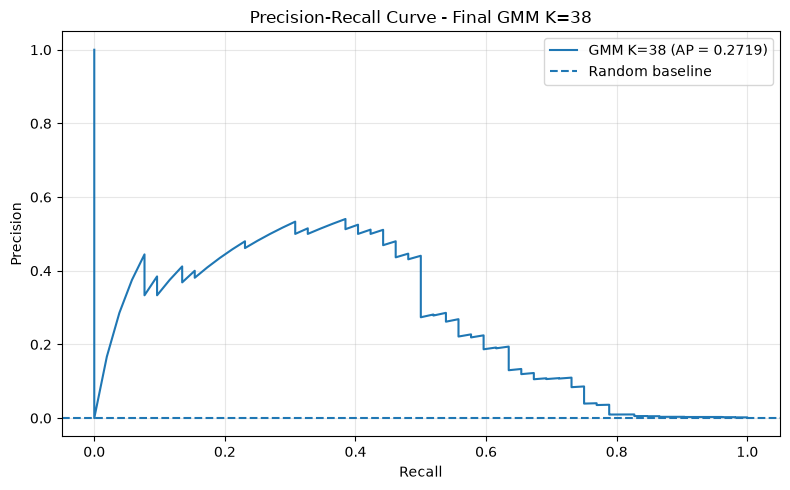

Final K=38 Test Average Precision: 0.27189213748376645


In [21]:


# 3. Final Precision-Recall Curve - GMM K=38

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Use final K=38 test scores and labels
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    final_test_labels,
    final_test_scores
)

# Calculate final K=38 Average Precision
final_test_ap = average_precision_score(
    final_test_labels,
    final_test_scores
)

# Plot Precision-Recall curve
plt.figure(figsize=(8, 5))

plt.plot(
    pr_recall,
    pr_precision,
    label=f"GMM K=38 (AP = {final_test_ap:.4f})"
)

# Random ranking baseline
plt.axhline(
    y=final_test_labels.mean(),
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Final GMM K=38")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Final K=38 Test Average Precision:", final_test_ap)

